# SkillBridge — Offline Evaluation Results

This notebook presents the evaluation of the SkillBridge recommenders for the project report.
Every number is read from the files that `src/evaluation.py` writes to `reports/`; nothing is typed in by hand.
Set `RERUN = True` in the next cell to recompute everything from the data (about 40 seconds).

**Important:** these are *offline* results on **proxy relevance labels** (experiments A and B) and on
**synthetic learners** (experiment C). No user study was carried out, so nothing here measures whether real
learners find the recommendations useful.

Figures are saved to `reports/figures/` so they can be inserted into the report.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():          # notebook opened from notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import METADATA_PATH, PAIRWISE_PATH, RESULTS_PATH, run_all

RERUN = False                                     # True = recompute every experiment
if RERUN or not RESULTS_PATH.exists():
    run_all()

FIGURES = PROJECT_ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
results = pd.read_csv(RESULTS_PATH)
pairwise = pd.read_csv(PAIRWISE_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
dataset = json.loads((PROJECT_ROOT / "reports" / "dataset_profile.json").read_text(encoding="utf-8"))

print("Results generated:", metadata["generated_at"])
print("Cut-off K:", metadata["k"], "| random seed:", metadata["random_seed"],
      "| bootstrap resamples:", metadata["bootstrap_resamples"])

Results generated: 2026-10-15T19:12:27+00:00
Cut-off K: 10 | random seed: 7 | bootstrap resamples: 1000


## 1. Dataset summary

In [3]:
pd.DataFrame({
    "Value": {
        "Raw rows x columns": f"{dataset['raw_rows']} x {len(dataset['raw_columns'])}",
        "Exact duplicate rows removed": dataset["raw_exact_duplicate_rows"],
        "Unique courses after cleaning": dataset["clean_rows"],
        "Courses with a genuine rating": dataset["rated_courses"],
        "'Not Calibrated' ratings (left unrated)": dataset["raw_non_numeric_ratings"].get("Not Calibrated", 0),
        "Providers": dataset["providers"],
        "Coursera subdomains": dataset["subdomains"],
        "Median description length (chars)": dataset["description_length_chars"]["50%"],
        "Mean rating": dataset["rating_summary"]["mean"],
    }
})

,Value
Raw rows x columns,3522 x 7
Exact duplicate rows removed,98
Unique courses after cleaning,3424
Courses with a genuine rating,3342
'Not Calibrated' ratings (left unrated),82
Providers,184
Coursera subdomains,45
Median description length (chars),1021.5
Mean rating,4.552


## 2. Metrics

For a ranked list *L* of the top *k* = 10 courses and the set *R* of relevant courses:

| Metric | Definition |
|---|---|
| Precision@10 | \|L ∩ R\| / 10 |
| Recall@10 | \|L ∩ R\| / \|R\| |
| NDCG@10 | DCG / ideal DCG, with DCG = Σ relᵢ / log₂(i + 1) — rewards relevant courses near the top |
| MRR@10 | 1 / rank of the first relevant course (0 if none) |
| HitRate@10 | 1 if at least one relevant course is in the top 10 |
| Catalogue coverage | share of the whole catalogue that appears in at least one list |
| Diversity (ILD) | mean pairwise cosine distance between the TF-IDF vectors of a list |
| Gap coverage@10 | share of the learner's missing skills taught by at least one recommended course |
| Level fit@10 | share of recommended courses whose difficulty equals the learner's level |
| Beginner-vs-Advanced overlap | Jaccard overlap of the top 10 when only the learner's level changes (1 = level ignored) |

In [4]:
BLUE, GREY, INK, MUTED = "#2a78d6", "#c3c2b7", "#14161a", "#8a8f98"
REFERENCE_ROWS = {"Random baseline", "Generator oracle (upper reference)"}
PERCENT_METRICS = {"Catalogue coverage", "HitRate@10", "Gap coverage@10", "Level fit@10"}


def table(experiment: str, metrics: list[str]) -> pd.DataFrame:
    subset = results[results["experiment"] == experiment]
    wide = subset.pivot_table(index="method", columns="metric", values="value", sort=False)[metrics]
    return wide.sort_values(metrics[0], ascending=False)


def bars(ax, experiment: str, metric: str) -> None:
    """Single-series horizontal bars, best on top; reference rows in grey; every bar labelled."""
    data = results[(results["experiment"] == experiment) & (results["metric"] == metric)]
    data = data.sort_values("value")
    colours = [GREY if m in REFERENCE_ROWS else BLUE for m in data["method"]]
    ax.barh(data["method"], data["value"], color=colours, height=0.6)
    fmt = "{:.0%}" if metric in PERCENT_METRICS else "{:.3f}"
    peak = data["value"].max()
    for y, value in enumerate(data["value"]):
        ax.text(value + peak * 0.02, y, fmt.format(value), va="center", fontsize=9, color=INK)
    ax.set_xlim(0, peak * 1.25 if peak > 0 else 1)
    ax.set_title(metric, loc="left", fontsize=11, color=INK, fontweight="bold")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GREY)
    ax.spines["bottom"].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.tick_params(axis="y", colors=INK)
    ax.grid(axis="x", color="#e6e5df", linewidth=0.8)
    ax.set_axisbelow(True)


def small_multiples(experiment: str, metrics: list[str], filename: str, columns: int = 2) -> None:
    rows = -(-len(metrics) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(6.2 * columns, 0.55 * 8 * rows + 0.6), squeeze=False)
    for ax, metric in zip(axes.flat, metrics):
        bars(ax, experiment, metric)
    for ax in list(axes.flat)[len(metrics):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=200, bbox_inches="tight")
    plt.show()

## 3. Experiment A — Similar courses (real catalogue, proxy label)

**Setup.** 400 randomly sampled query courses. For each, a method returns 10 "similar" courses. A returned course
counts as relevant if it has the **same Coursera subdomain** as the query. Subdomains are editorial labels and are
*not* part of the TF-IDF text, so the label is independent of the model input — but "same subdomain" is only a
proxy for "a useful similar course".

In [5]:
table("A. Similar courses", ["NDCG@10", "Precision@10", "MRR@10", "HitRate@10", "Diversity (ILD)", "Catalogue coverage"])

metric,NDCG@10,Precision@10,MRR@10,HitRate@10,Diversity (ILD),Catalogue coverage
method,,,,,,
Content-based,0.563,0.522,0.799,0.948,0.852,0.629
Random baseline,0.039,0.037,0.110,0.307,0.985,0.687
Top-rated baseline,0.035,0.040,0.063,0.265,0.973,0.003


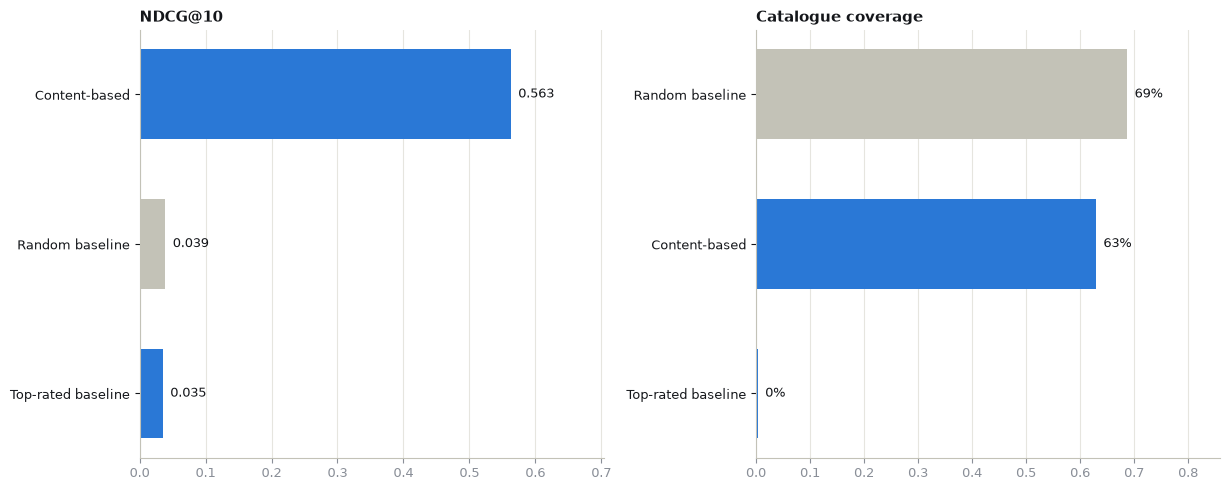

In [6]:
small_multiples("A. Similar courses", ["NDCG@10", "Catalogue coverage"], "experiment_a_similar_courses.png")

## 4. Experiment B — Learner profiles (real catalogue, proxy labels)

**Setup.** 99 profiles: 11 career goals × 3 levels (Beginner, Intermediate, Advanced) × 3 shares of the career's
skills already known (none, a third, two thirds).

**Two proxy labels** (neither is used by any recommender):
* *Topic only* — a course is relevant if its Coursera subdomain is one the career is mapped to in
  `config/skill_knowledge.json`. This ignores whether the course suits the learner's level.
* *Topic + level (graded)* — gain 2 if the course is on-topic **and** at the learner's level, 1 if on-topic at an
  adjacent level, 0 otherwise. NDCG with graded gains is standard in information retrieval; this label reflects
  SkillBridge's goal of courses that fit both the career and the learner.

**How the hybrid weights were chosen (no test leakage).** Career-split cross-validation: the 11 careers are split
into two folds; the content / knowledge / rating weights are chosen on one fold by graded NDCG@10 and applied
only to profiles of the *other* fold. The "Hybrid (cross-validated)" row therefore contains only held-out scores.
"Hybrid (hand-set weights)" is the earlier version (0.35 / 0.45 / 0.20) for comparison, and
"+ diversity" is the website's setting, which re-ranks with Maximal Marginal Relevance (λ = 0.85) to remove
near-duplicate courses.

In [7]:
b = metadata["experiment_B"]
print("Folds:", {fold: [c for c, f in b["fold_of_career"].items() if f == int(fold)] for fold in b["fold_selections"]})
for fold, choice in b["fold_selections"].items():
    print(f"Fold {fold} weights chosen on the other careers:", choice["weights"])
print("Weights used by the website (chosen on all careers):", b["selected_for_application"]["weights"])
table("B. Learner profiles", ["NDCG@10 (topic + level)", "NDCG@10", "Level fit@10", "Gap coverage@10",
                              "Beginner-vs-Advanced overlap (Jaccard)", "Diversity (ILD)", "Catalogue coverage"])

Folds: {'0': ['Business Analyst', 'Cybersecurity Analyst', 'Data Scientist', 'Machine Learning Engineer', 'Software Engineer', 'Web Developer'], '1': ['Cloud & DevOps Engineer', 'Data Analyst', 'Digital Marketer', 'Product Manager', 'UX Designer']}
Fold 0 weights chosen on the other careers: {'content': 0.1, 'knowledge': 0.7, 'quality': 0.1}
Fold 1 weights chosen on the other careers: {'content': 0.1, 'knowledge': 0.5, 'quality': 0.0}
Weights used by the website (chosen on all careers): {'content': 0.1, 'knowledge': 0.7, 'quality': 0.1}


metric,NDCG@10 (topic + level),NDCG@10,Level fit@10,Gap coverage@10,Beginner-vs-Advanced overlap (Jaccard),Diversity (ILD),Catalogue coverage
method,,,,,,,
Hybrid (cross-validated),0.650,0.701,0.852,0.960,0.010,0.903,0.123
Hybrid (cross-validated) + diversity,0.626,0.672,0.860,0.974,0.011,0.928,0.123
Knowledge-based,0.563,0.586,0.900,0.955,0.003,0.919,0.118
Hybrid (hand-set weights),0.550,0.747,0.593,0.953,0.268,0.884,0.091
Content-based,0.405,0.778,0.333,0.919,1.000,0.873,0.056
Top-rated baseline,0.096,0.192,0.333,0.360,1.000,0.973,0.003
Random baseline,0.057,0.103,0.313,0.339,0.000,0.985,0.249


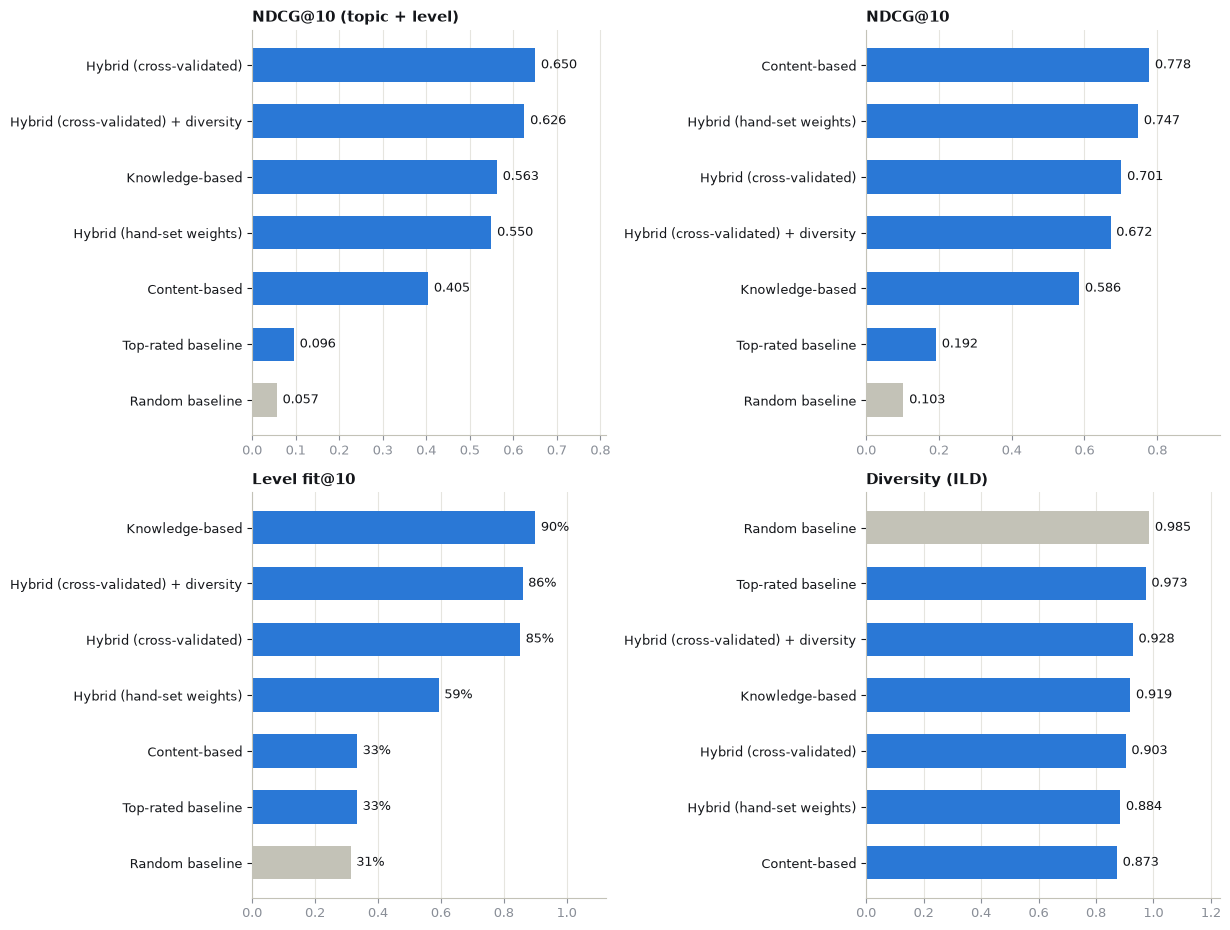

In [8]:
small_multiples("B. Learner profiles", ["NDCG@10 (topic + level)", "NDCG@10", "Level fit@10", "Diversity (ILD)"],
                "experiment_b_learner_profiles.png")

## 5. Experiment C — Interaction prediction (SYNTHETIC data)

> ⚠️ **Synthetic data.** The catalogue has no real learner–course interactions, so `src/synthetic_data.py`
> generates 1,200 simulated learners. These results show how well each method recovers the generator's patterns.
> They are **not** evidence about real learner behaviour.

**Setup.** Each learner's latest 20% of courses is held out as the test set; models are trained on the rest.
Collaborative-filtering settings and hybrid weights were chosen on a validation split taken from the *training*
data only. The **generator oracle** ranks courses with the generator's own hidden sampling weights: it is not a
recommender, but it shows the best score achievable on this noisy task.

In [9]:
c = metadata["experiment_C"]
print(f"Train / test interactions: {c['train_interactions']:,} / {c['test_interactions']:,} for {c['learners']:,} learners")
print("CF settings chosen on validation:", c["cf_params"])
print("Hybrid weights chosen on validation:", c["hybrid_weights"])
table("C. Synthetic interactions", ["NDCG@10", "Precision@10", "Recall@10", "MRR@10", "HitRate@10", "Catalogue coverage"])

Train / test interactions: 9,688 / 2,420 for 1,200 learners
CF settings chosen on validation: {'n_neighbours': 400, 'shrinkage': 50.0}
Hybrid weights chosen on validation: {'content': 0.25, 'knowledge': 1.0, 'quality': 0.5, 'collaborative': 1.0}


metric,NDCG@10,Precision@10,Recall@10,MRR@10,HitRate@10,Catalogue coverage
method,,,,,,
Generator oracle (upper reference),0.071,2.283e-02,0.111,8.185e-02,0.203,0.054
Most-completed (synthetic popularity),0.020,7.083e-03,0.036,2.131e-02,0.069,0.004
Hybrid (tuned on validation),0.018,5.750e-03,0.029,2.012e-02,0.056,0.288
Item-kNN CF,0.014,4.667e-03,0.023,1.631e-02,0.046,0.553
Hybrid (default weights),0.014,4.750e-03,0.023,1.608e-02,0.047,0.142
Knowledge-based (persona),0.009,3.500e-03,0.017,8.426e-03,0.035,0.103
Content-based (history),0.005,2.000e-03,0.010,4.027e-03,0.020,0.532
Random baseline,0.002,7.500e-04,0.003,1.783e-03,0.007,0.966
Top-rated baseline,0.001,5.833e-04,0.003,8.773e-04,0.006,0.022


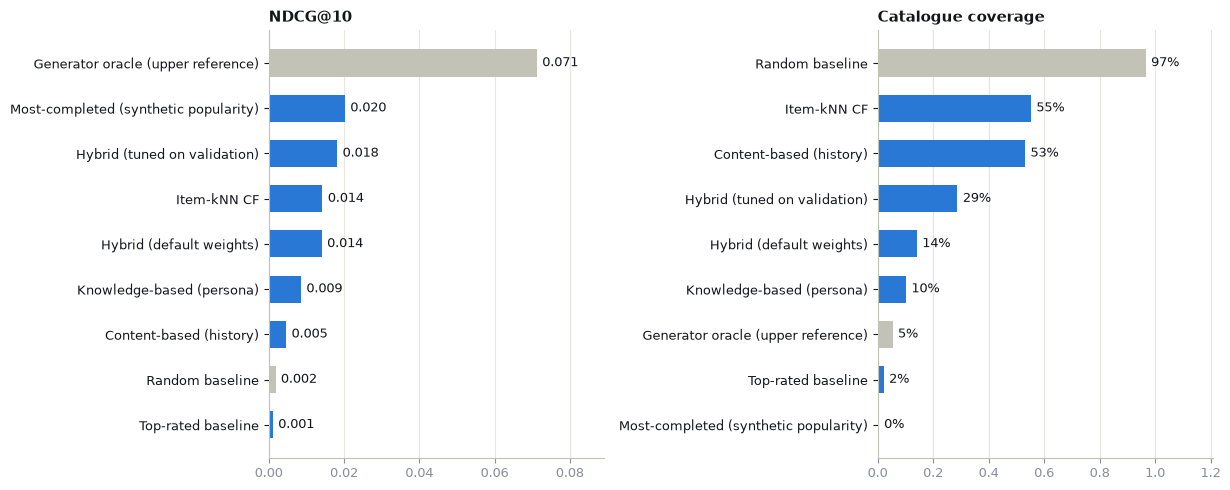

In [10]:
small_multiples("C. Synthetic interactions", ["NDCG@10", "Catalogue coverage"], "experiment_c_synthetic.png")

## 6. Comparing the recommender systems

The experiments above score each system separately. This section puts them **side by side**: what each system
uses, how it behaves for the same learner, and how much their recommendation lists overlap.

| System | Technique | Signals it uses | Where it appears | Strength | Weakness |
|---|---|---|---|---|---|
| Top-rated baseline | Non-personalised ranking | Average course rating | Notebook only | Simple, stable reference point | Same list for every learner; the dataset has no rating counts |
| Content-based | TF-IDF + cosine similarity | Course text vs. the learner's goal and interests | *Match my interests*, *Similar courses* | Finds on-topic courses; explainable by shared terms | Ignores the learner's level; can return near-duplicates |
| Knowledge-based | Explicit rules over a hand-written skill map | Skill gaps, prerequisites, level | *Fill my skill gaps*, Skill gaps page | Fits the learner's level; explains every gap | Depends on the hand-written map and noisy skill tags |
| Collaborative (item-kNN) | Learner–course co-occurrence | Course histories of **synthetic** learners | Notebook only | Learns patterns that course text cannot show | Needs real interaction data; cold start for new learners |
| Hybrid | Weighted combination + MMR diversity | Knowledge, content and rating signals | *Best match*, Skill gaps, Learning path | Best held-out graded relevance (experiment B) | Lower topic-only NDCG than content-based |

### 6.1 Same learner, different systems

One learner — a beginner aiming to become a Data Scientist who knows Python and has completed one course — ranked by
every system. The collaborative list uses the synthetic learner population, so it is shown for illustration only.

In [11]:
from copy import deepcopy

from src.profile import LearnerProfile
from src.recommender import COLLABORATIVE, CONTENT, HYBRID, KNOWLEDGE, TOP_RATED, SkillBridgeEngine

engine = SkillBridgeEngine.load()
example = LearnerProfile(career_goal="Data Scientist", current_skills=["Python Programming"], proficiency="Beginner",
                         interests="data analysis with python, statistics, machine learning projects",
                         completed_course_ids=["python-data"])
systems = {
    "Hybrid (website)": dict(method=HYBRID, use_collaborative=False),
    "Knowledge-based": dict(method=KNOWLEDGE),
    "Content-based": dict(method=CONTENT),
    "Collaborative (synthetic)": dict(method=COLLABORATIVE),
    "Top-rated": dict(method=TOP_RATED),
}
TOP_N = 5
side_by_side = {name: engine.recommend(deepcopy(example), n=TOP_N, **options).table for name, options in systems.items()}
comparison = pd.DataFrame({name: ranked["title"].tolist() + [""] * (TOP_N - len(ranked))
                           for name, ranked in side_by_side.items()}, index=range(1, TOP_N + 1))
hybrid_ids = set(side_by_side["Hybrid (website)"]["course_id"])
for name, ranked in side_by_side.items():
    if name != "Hybrid (website)":
        print(f"{name:<28} shares {len(hybrid_ids & set(ranked['course_id']))}/{TOP_N} courses with the hybrid")
comparison

Knowledge-based              shares 4/5 courses with the hybrid
Content-based                shares 2/5 courses with the hybrid
Collaborative (synthetic)    shares 0/5 courses with the hybrid
Top-rated                    shares 0/5 courses with the hybrid


,Hybrid (website),Knowledge-based,Content-based,Collaborative (synthetic),Top-rated
1,Exploratory Data Analysis,Analyze Box Office Data with Seaborn and Python,Exploratory Data Analysis,Distributed Programming in Java,Design Computing: 3D Modeling in Rhinoceros wi...
2,Data for Machine Learning,SQL for Data Science Capstone Project,Statistical Data Visualization in Python,The Development of Mobile Health Monitoring Sy...,Acing the Product Management Interview
3,Analyze Box Office Data with Seaborn and Python,Data for Machine Learning,Applied Data Science Capstone,Software Requirements Prioritization: Risk Ana...,Digitalisation in Aeronautics
4,SQL for Data Science Capstone Project,Exploratory Data Analysis,First Steps in Linear Algebra for Machine Lear...,Build a Table Layout App in Android Studio,Agile Projects: Defining Epics and Mapping Val...
5,Getting Started with SAS Programming,Principal Component Analysis with NumPy,SQL for Data Science Capstone Project,Construction Scheduling,Artificial Intelligence Ethics in Action


### 6.2 How much do the systems agree?

For all 99 evaluation profiles of experiment B, the top-10 lists of each pair of systems are compared with the
Jaccard overlap (|A ∩ B| / |A ∪ B|), then averaged. 1.00 means identical lists, 0.00 means no course in common.
High overlap is neither good nor bad: it shows which systems behave alike. Collaborative filtering is left out
because these profiles have no course history.

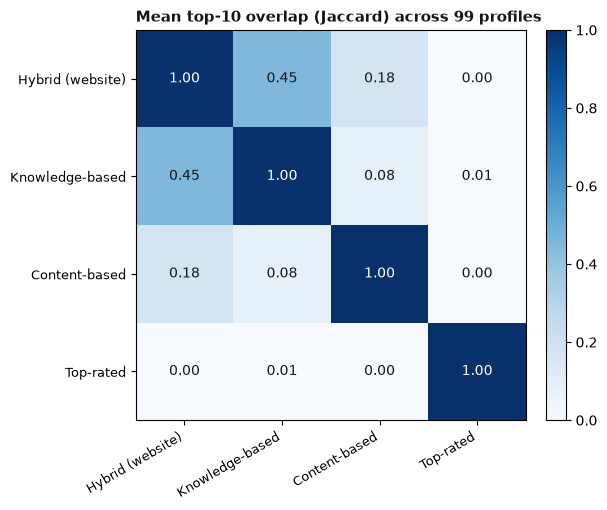

,Hybrid (website),Knowledge-based,Content-based,Top-rated
Hybrid (website),1.00,0.45,0.18,0.00
Knowledge-based,0.45,1.00,0.08,0.01
Content-based,0.18,0.08,1.00,0.00
Top-rated,0.00,0.01,0.00,1.00


In [12]:
import itertools

import numpy as np

from src.evaluation import generate_evaluation_profiles, jaccard

compared = {"Hybrid (website)": dict(method=HYBRID, use_collaborative=False),
            "Knowledge-based": dict(method=KNOWLEDGE), "Content-based": dict(method=CONTENT),
            "Top-rated": dict(method=TOP_RATED)}
top_lists = {name: [] for name in compared}
for _, profile in generate_evaluation_profiles(engine):
    for name, options in compared.items():
        top_lists[name].append(engine.recommend(deepcopy(profile), n=10, **options).table["course_id"].tolist())

names = list(compared)
overlap = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for a, b in itertools.combinations(names, 2):
    value = float(np.mean([jaccard(x, y) for x, y in zip(top_lists[a], top_lists[b])]))
    overlap.loc[a, b] = overlap.loc[b, a] = value

fig, ax = plt.subplots(figsize=(6.4, 5.2))
image = ax.imshow(overlap.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(len(names)), names, fontsize=9)
for i in range(len(names)):
    for j in range(len(names)):
        value = overlap.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                color="white" if value > 0.55 else INK)
ax.set_title("Mean top-10 overlap (Jaccard) across 99 profiles", loc="left", fontsize=11, color=INK, fontweight="bold")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIGURES / "method_overlap.png", dpi=200, bbox_inches="tight")
plt.show()
overlap.round(2)

### 6.3 Scorecard

The main experiment-B measures for each system in one table (hybrid rows are held-out, cross-validated scores). The
best value in each column is highlighted. No single system wins every column, which is why the website combines them.

In [13]:
scorecard_metrics = ["NDCG@10 (topic + level)", "NDCG@10", "Level fit@10", "Gap coverage@10", "Diversity (ILD)",
                     "Catalogue coverage"]
scorecard = table("B. Learner profiles", scorecard_metrics).drop(index=["Random baseline"], errors="ignore")
scorecard.style.format("{:.3f}").highlight_max(axis=0, props="background-color: #dbe9fb; font-weight: 700")

metric,NDCG@10 (topic + level),NDCG@10,Level fit@10,Gap coverage@10,Diversity (ILD),Catalogue coverage
method,,,,,,
Hybrid (cross-validated),0.650,0.701,0.852,0.960,0.903,0.123
Hybrid (cross-validated) + diversity,0.626,0.672,0.860,0.974,0.928,0.123
Knowledge-based,0.563,0.586,0.900,0.955,0.919,0.118
Hybrid (hand-set weights),0.550,0.747,0.593,0.953,0.884,0.091
Content-based,0.405,0.778,0.333,0.919,0.873,0.056
Top-rated baseline,0.096,0.192,0.333,0.360,0.973,0.003


## 7. Are the differences real? Paired bootstrap

For each comparison *A − B*, the per-unit NDCG@10 differences (queries, profiles or learners) are resampled with
replacement 1,000 times and the 2.5th and 97.5th percentiles of the mean form a 95% interval. An interval that does
not include 0 suggests a real difference *under this offline setup*. No correction for multiple comparisons is
applied.

In [14]:
pairwise[["experiment", "comparison", "difference", "ci_low", "ci_high", "n", "ci_excludes_zero"]]

,experiment,comparison,difference,ci_low,ci_high,n,ci_excludes_zero
0,A. Similar courses,Content-based - Top-rated baseline,0.528,4.961e-01,5.570e-01,400,True
1,A. Similar courses,Content-based - Random baseline,0.524,4.918e-01,5.528e-01,400,True
2,B. Learner profiles,Hybrid (cross-validated) - Content-based,0.246,2.025e-01,2.919e-01,99,True
3,B. Learner profiles,Hybrid (cross-validated) - Knowledge-based,0.088,5.541e-02,1.184e-01,99,True
4,B. Learner profiles,Hybrid (cross-validated) - Hybrid (hand-set we...,0.101,7.150e-02,1.329e-01,99,True
5,B. Learner profiles,Hybrid (cross-validated) - Content-based,-0.076,-1.124e-01,-4.101e-02,99,True
6,B. Learner profiles,Hybrid (cross-validated) - Top-rated baseline,0.554,4.994e-01,6.068e-01,99,True
7,B. Learner profiles,Hybrid (cross-validated) + diversity - Hybrid ...,-0.025,-3.973e-02,-1.049e-02,99,True
8,B. Learner profiles,Hybrid (cross-validated) + diversity - Hybrid ...,0.025,2.041e-02,2.925e-02,99,True
9,C. Synthetic interactions,Hybrid (tuned on validation) - Item-kNN CF,0.004,-2.381e-04,7.921e-03,1200,False


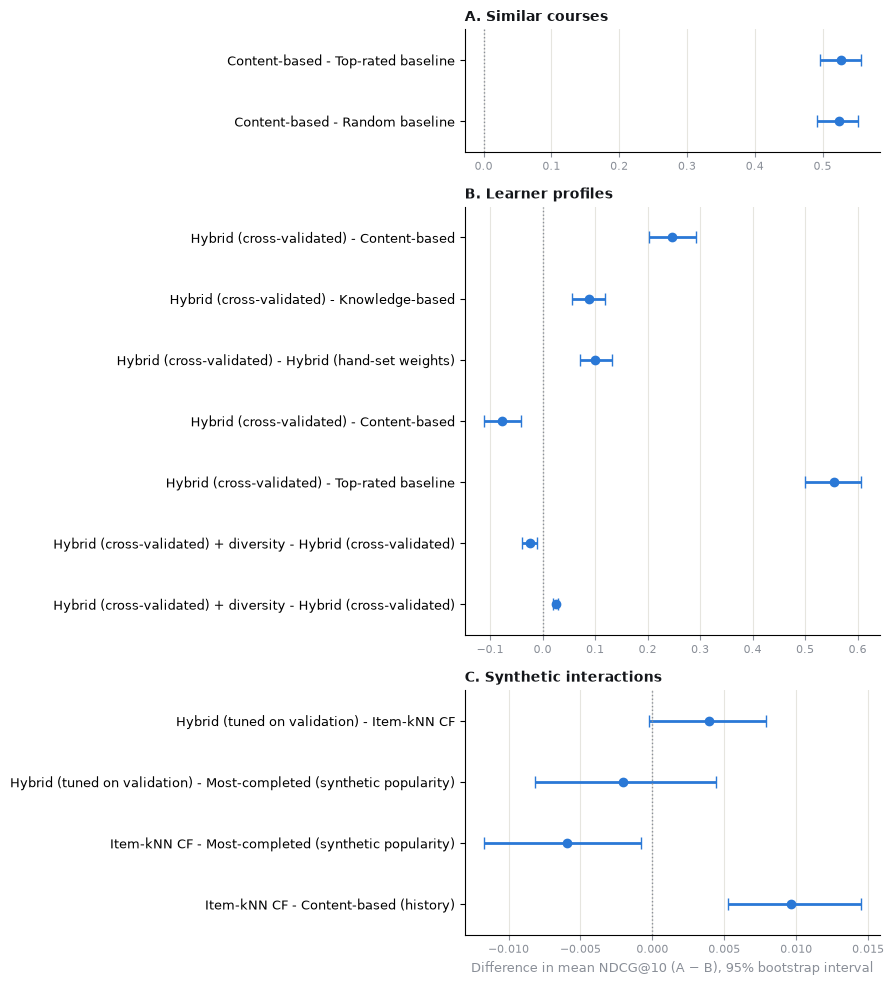

In [15]:
# One panel per experiment: the differences in C are ~100x smaller than in A/B, so each gets its own scale.
experiments = list(dict.fromkeys(pairwise["experiment"]))
fig, axes = plt.subplots(len(experiments), 1, figsize=(9, 1.0 + 0.55 * len(pairwise) + 0.6 * len(experiments)),
                         gridspec_kw={"height_ratios": [max(2, (pairwise["experiment"] == e).sum()) for e in experiments]})
for ax, experiment in zip(axes, experiments):
    part = pairwise[pairwise["experiment"] == experiment].reset_index(drop=True)
    y = range(len(part))
    ax.errorbar(part["difference"], y,
                xerr=[part["difference"] - part["ci_low"], part["ci_high"] - part["difference"]],
                fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4, markersize=6)
    ax.axvline(0, color=MUTED, linestyle=":", linewidth=1)
    ax.set_yticks(list(y), part["comparison"], fontsize=9)
    ax.set_ylim(len(part) - 0.5, -0.5)
    ax.set_title(experiment, loc="left", fontsize=10, color=INK, fontweight="bold")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="x", color="#e6e5df", linewidth=0.8)
    ax.tick_params(axis="x", colors=MUTED, labelsize=8)
axes[-1].set_xlabel("Difference in mean NDCG@10 (A − B), 95% bootstrap interval", fontsize=9, color=MUTED)
fig.tight_layout()
fig.savefig(FIGURES / "pairwise_bootstrap.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Skills taught together (association rule mining)

Apriori over the catalogue: each course is a transaction and the knowledge-base skills it teaches are the items.
This describes **how courses are built**, not learner behaviour (there is no enrolment data), so the rules are not
used to rank courses.

* support(A → B) = share of courses teaching both A and B
* confidence(A → B) = support(A and B) / support(A)
* lift(A → B) = confidence(A → B) / support(B); lift > 1 means A and B appear together more often than chance

In [16]:
from src.association_rules import mine_skill_rules
from src.recommender import SkillBridgeEngine

rules = mine_skill_rules(SkillBridgeEngine.load().skill_matrix)
print(f"{len(rules)} rules with support ≥ 1%, confidence ≥ 30% and lift > 1")
rules.head(15)

29 rules with support ≥ 1%, confidence ≥ 30% and lift > 1


,antecedent,consequent,support,confidence,lift
0,HTML & CSS,Web Development,0.019,0.648,15.11
1,Web Development,HTML & CSS,0.019,0.438,15.11
2,HTML & CSS,JavaScript,0.014,0.493,14.20
3,JavaScript,HTML & CSS,0.014,0.412,14.20
4,JavaScript,Web Development,0.017,0.494,11.52
5,Web Development,JavaScript,0.017,0.400,11.52
6,Computer Vision,Deep Learning,0.014,0.636,10.05
7,Digital Marketing,Marketing Fundamentals,0.032,0.767,9.03
8,Marketing Fundamentals,Digital Marketing,0.032,0.380,9.03
9,Data Visualization,Data Analysis,0.015,0.487,6.06


## 9. Key findings

In [17]:
def value(experiment, method, metric):
    row = results[(results["experiment"] == experiment) & (results["method"] == method) & (results["metric"] == metric)]
    return float(row["value"].iloc[0])

A, B, C = "A. Similar courses", "B. Learner profiles", "C. Synthetic interactions"
print(f"A  Content-based similar courses: NDCG@10 {value(A, 'Content-based', 'NDCG@10'):.3f} "
      f"vs random {value(A, 'Random baseline', 'NDCG@10'):.3f}")
for method in ["Hybrid (cross-validated) + diversity", "Hybrid (cross-validated)", "Hybrid (hand-set weights)",
               "Knowledge-based", "Content-based", "Top-rated baseline"]:
    print(f"B  {method:<38} graded NDCG {value(B, method, 'NDCG@10 (topic + level)'):.3f}"
          f" | topic NDCG {value(B, method, 'NDCG@10'):.3f} | level fit {value(B, method, 'Level fit@10'):.0%}"
          f" | diversity {value(B, method, 'Diversity (ILD)'):.3f}")
for method in ["Generator oracle (upper reference)", "Most-completed (synthetic popularity)",
               "Hybrid (tuned on validation)", "Item-kNN CF", "Content-based (history)"]:
    print(f"C  {method:<40} NDCG@10 {value(C, method, 'NDCG@10'):.4f}")

A  Content-based similar courses: NDCG@10 0.563 vs random 0.039
B  Hybrid (cross-validated) + diversity   graded NDCG 0.626 | topic NDCG 0.672 | level fit 86% | diversity 0.928
B  Hybrid (cross-validated)               graded NDCG 0.650 | topic NDCG 0.701 | level fit 85% | diversity 0.903
B  Hybrid (hand-set weights)              graded NDCG 0.550 | topic NDCG 0.747 | level fit 59% | diversity 0.884
B  Knowledge-based                        graded NDCG 0.563 | topic NDCG 0.586 | level fit 90% | diversity 0.919
B  Content-based                          graded NDCG 0.405 | topic NDCG 0.778 | level fit 33% | diversity 0.873
B  Top-rated baseline                     graded NDCG 0.096 | topic NDCG 0.192 | level fit 33% | diversity 0.973
C  Generator oracle (upper reference)       NDCG@10 0.0712
C  Most-completed (synthetic popularity)    NDCG@10 0.0202
C  Hybrid (tuned on validation)             NDCG@10 0.0182
C  Item-kNN CF                              NDCG@10 0.0143
C  Content-based (hist

**Reading the results honestly**

* **A — similar courses.** TF-IDF nearest neighbours agree with Coursera's own subject labels far more often than
  random or top-rated lists, so the content model captures topical similarity.
* **B — learner profiles.** Choosing the hybrid's weights by career-split cross-validation improved it clearly
  over the earlier hand-set weights on the graded topic-and-level label, and the cross-validated hybrid is
  significantly better than content-based and knowledge-based alone on that label (see the bootstrap table). The
  cost is on the *topic-only* label, where content-based remains best: it finds on-topic courses but ignores the
  learner's level (level fit 33%, and identical lists for Beginner and Advanced learners). The website's
  diversification lowers graded NDCG slightly while making lists measurably more varied — a deliberate trade-off
  to avoid near-duplicate courses.
* **C — synthetic learners.** The task is very noisy: even the generator's own weights reach a low NDCG. Simple
  popularity (completion counts) is the strongest method, item-kNN CF is significantly below it, and the tuned
  hybrid cannot be distinguished from either. CF does beat content-based history and covers far more of the
  catalogue than popularity. Because the data are simulated, these findings describe the algorithms' behaviour, not
  real learners.

**Limitations.** Proxy labels (A, B), simulated interactions (C), noisy auto-generated skill tags in the dataset, a
hand-written career-skill mapping, and no user study. Offline metrics cannot show whether learners trust the
explanations or learn more.